# Unsupervised Machine Learning
- Unsupervised machine learning is a branch of artificial intelligence where models are trained on input data without explicit output labels or target variables. The objective is to uncover patterns, structures, or relationships within the data itself. Unlike supervised learning, where the model learns from labeled data, unsupervised learning deals with unlabeled data or seeks to find inherent patterns without specific guidance.

# Core Concepts in Unsupervised Learning:
- **No Target Variable:** In unsupervised learning, there's no predefined output to predict or guide the learning process. The algorithm explores the inherent structure or patterns within the data.

- **Exploratory Analysis:** Algorithms in unsupervised learning aim to explore and understand the underlying structure of data. This can involve tasks such as clustering, dimensionality reduction, density estimation, and more.

# Examples of Unsupervised Learning:
### Clustering
- **K-means:** Divides data into 'k' clusters based on similarity.
Hierarchical Clustering: Builds a hierarchy of clusters.
- Example: Grouping customers based on purchasing behavior without any predefined segments.

### Dimensionality Reduction:
- **Principal Component Analysis (PCA):** Reduces the number of variables while retaining key information.

### Anomaly Detection:
- **Isolation Forest:** Identifies outliers in data that significantly differ from the norm.
- Example: Detecting fraudulent transactions in a financial dataset without labeled fraud instances.

# Kmeans Clustering
- K-means clustering is an unsupervised machine learning algorithm used for partitioning a dataset into K distinct, non-overlapping clusters. It's widely used for data segmentation, pattern recognition, and exploratory data analysis. Here's a detailed explanation of how K-means clustering works:

### How K-means Works:
#### 1. Initialization:
- **Step 1:** Choose the number of clusters (K) that you want to identify in the dataset.
- **Step 2:** Initialize K centroids (cluster centers). These can be chosen randomly from the dataset or using a specific initialization method (e.g., k-means++).
#### 2. Assignment:
- **Step 3:** Assign each data point to the nearest centroid, creating K clusters. The assignment is typically done based on distance metrics, commonly using Euclidean distance.
- **Step 4:** Calculate the distance between each data point and each centroid. Assign each data point to the cluster associated with the nearest centroid.
#### 3. Update Centroids:
- **Step 5:** Recalculate the centroids of the clusters. Each centroid is repositioned to the mean (average) of all data points assigned to that cluster.
- **Step 6:** Update the centroids' positions based on the new assignments.
#### 4. Iteration:
- **Step 7:** Repeat steps 3 to 6 iteratively until convergence. Convergence happens when either the centroids no longer change significantly or after a specified number of iterations.

### Key Points:
- **Objective:** Minimize the sum of distances (usually squared distances, known as within-cluster sum of squares or WCSS) between data points and their respective cluster centroids.
- **Local Minimum:** K-means can converge to a local minimum, resulting in suboptimal clustering. Different initializations or multiple runs can mitigate this issue.
- **Sensitivity to Initial Centroids:** The algorithm's performance can be sensitive to the initial placement of centroids.
- **Number of Clusters (K):** Selecting the right number of clusters is crucial. Techniques like the Elbow Method or Silhouette Score can help determine an optimal K.

### Limitations:
- **Assumes Spherical Clusters:** K-means assumes that clusters are spherical and equally sized, which might not always hold in real-world data.
- **Sensitive to Outliers:** Outliers can significantly impact centroid calculation and cluster assignments.
- **Requires Specifying K:** You need to know or estimate the number of clusters beforehand, which might not always be straightforward.

In [ ]:
# importing libraries
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# generating data for clustering
data, _ = make_blobs(n_samples=300, centers=4, cluster_std=1, random_state=42)

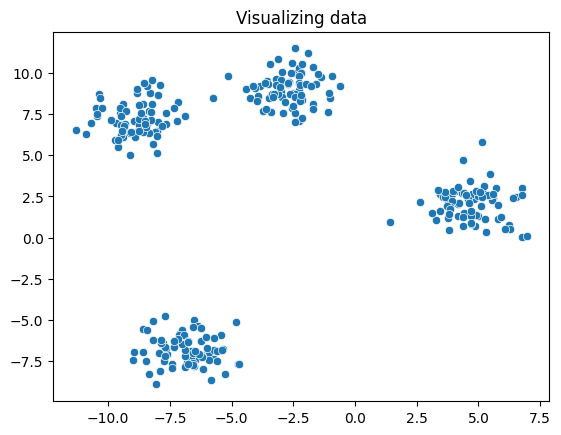

In [ ]:
sns.scatterplot(x=data[:,0],y=data[:,1])
plt.title("Visualizing data")
plt.show()

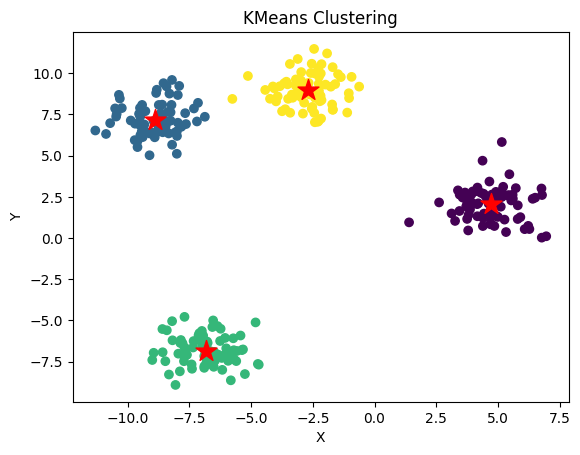

In [ ]:
# Initialize KMeans with K clusters
kmeans = KMeans(n_clusters=4)

# Fit KMeans to the data
kmeans.fit(data)

# Getting cluster labels
labels = kmeans.labels_

# Getting cluster centers
centers = kmeans.cluster_centers_

# Plotting the clusters
plt.scatter(data[:,0], data[:,1], c=labels, cmap='viridis')
plt.scatter(centers[:, 0], centers[:, 1], marker='*', c='red', s=250)
plt.title('KMeans Clustering')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()


In [ ]:
# generating data for clustering
data1, _ = make_blobs(n_samples=300, centers=4, cluster_std=2, random_state=42)

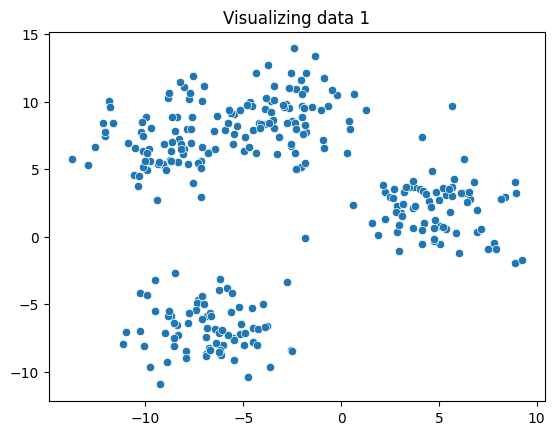

In [ ]:
sns.scatterplot(x=data1[:,0],y=data1[:,1])
plt.title("Visualizing data 1")
plt.show()

# Elbow Method and Determining the Number of Clusters:
- The Elbow Method helps in finding the optimal number of clusters for K-means by plotting the variance explained as a function of the number of clusters. The plot typically forms an "elbow," indicating the point where the incremental gain of adding more clusters decreases significantly.

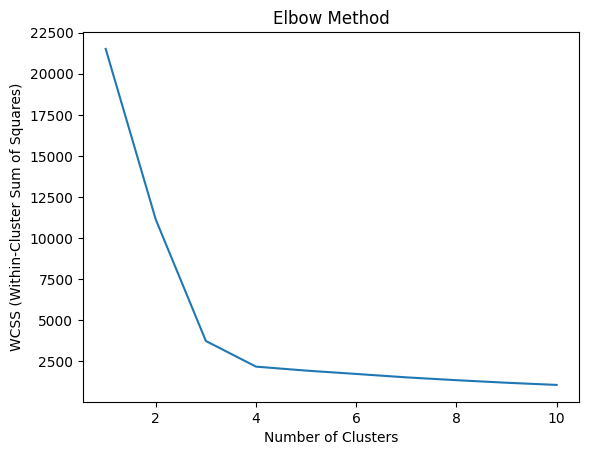

In [ ]:
# Using the Elbow Method to find the optimal number of clusters
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(data1)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Method graph
plt.plot(range(1, 11), wcss)
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.show()


# Silhouette Score
- The Silhouette Score is a metric used to measure the quality of clusters created by a clustering algorithm, such as K-means. It quantifies how well-separated the clusters are and how similar the data points are within the same cluster compared to other clusters. A higher silhouette score indicates better-defined clusters.

In [ ]:
# Generating sample data (replace this with your data)
data, _ = make_blobs(n_samples=300, centers=4, cluster_std=1.0, random_state=42)

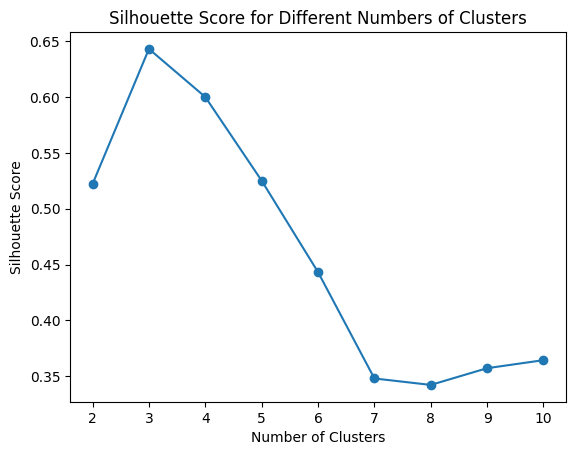

In [ ]:
# Calculate silhouette score for different number of clusters
silhouette_scores = []
for n_clusters in range(2, 11):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(data1)
    silhouette_avg = silhouette_score(data1, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Plotting silhouette scores for different cluster counts
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different Numbers of Clusters')
plt.show()


# Iris Data For unsupervised learning example

In [ ]:
# fething the iris data from seaborn library
iris = sns.load_dataset("iris")

In [ ]:
# checking the data
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


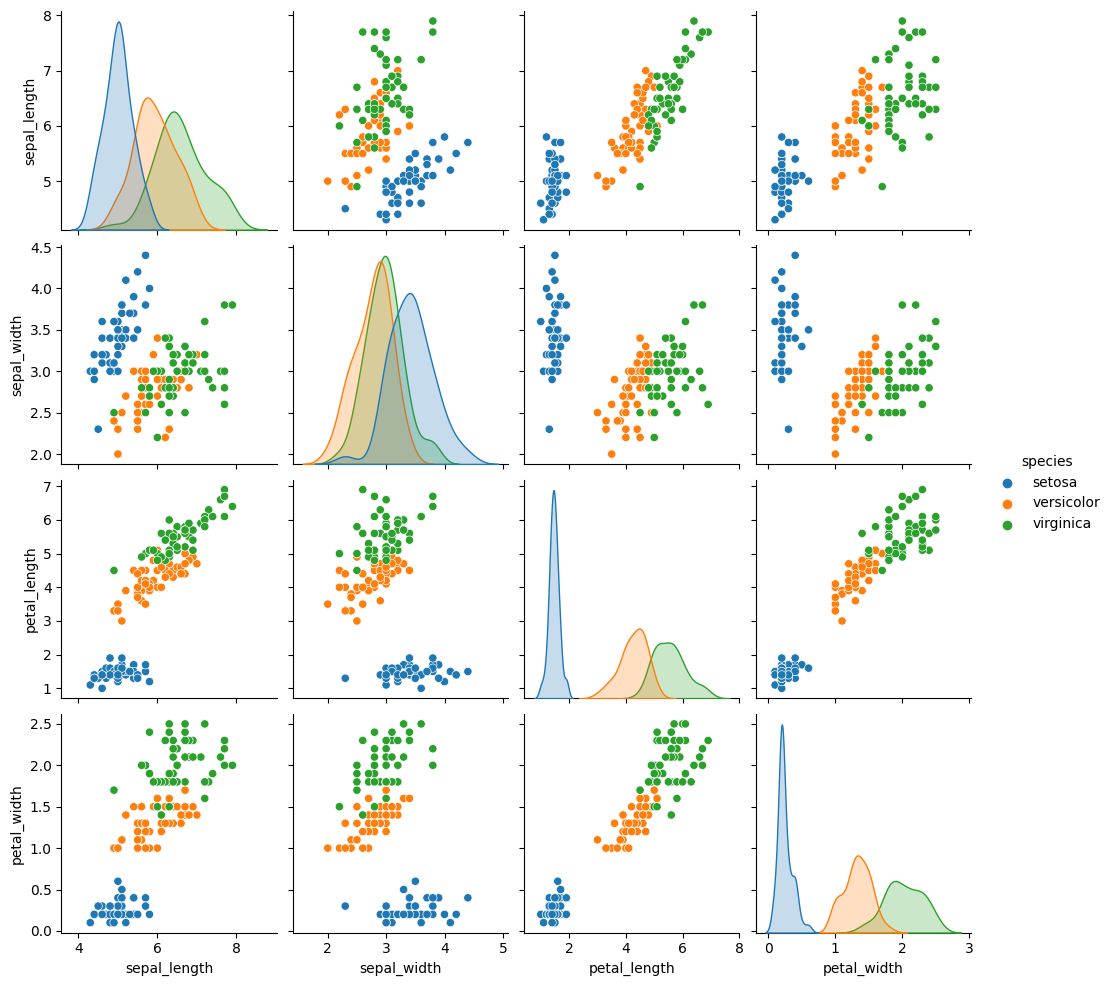

In [ ]:
# making a pairplot to analyze data
sns.pairplot(iris,hue="species")

In [ ]:
df = iris.drop("species",axis=1)

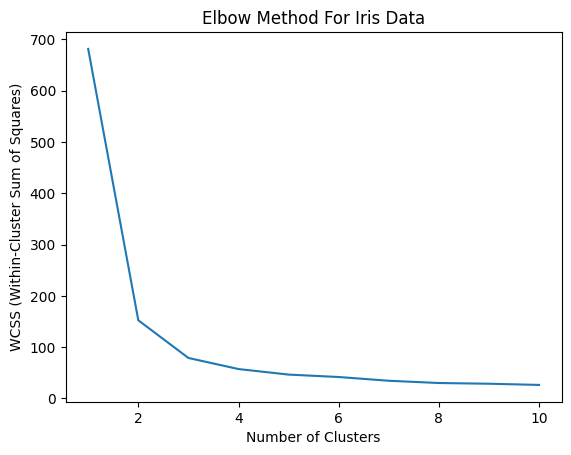

In [ ]:
# Using the Elbow Method to find the optimal number of clusters
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(df)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Method graph
plt.plot(range(1, 11), wcss)
plt.title('Elbow Method For Iris Data')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.show()


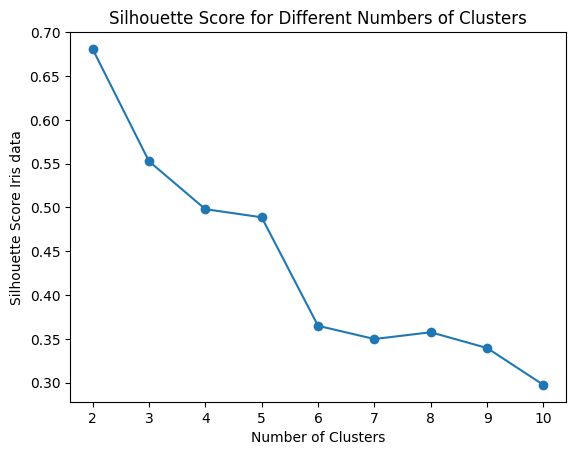

In [ ]:
# Calculate silhouette score for different number of clusters
silhouette_scores_iris = []
for n_clusters in range(2, 11):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(df)
    silhouette_avg = silhouette_score(df, cluster_labels)
    silhouette_scores_iris.append(silhouette_avg)

# Plotting silhouette scores for different cluster counts
plt.plot(range(2, 11), silhouette_scores_iris, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score Iris data')
plt.title('Silhouette Score for Different Numbers of Clusters')
plt.show()
